# Explorative Analyse: Warendorfer Straße

Tageswerte der Zählstelle 100034983, erzeugt mit `python -m radmuenster`.

Ziel dieses Notebooks: die Daten kennenlernen, bevor wir Features und Modelle bauen.
Wochenmuster, Saison, Corona, Ausreißer und unmarkierte Ausfälle.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# VS Code runs notebooks with the notebook's folder as working directory,
# so the project root is one level up.
DATA = Path("..") / "data" / "processed" / "daily_100034983.parquet"

daily = pd.read_parquet(DATA)
daily.head()

,count,count_in,count_out,n_intervals,n_flagged,one_way_dead,complete
date,,,,,,,
2019-01-01,1195,772.0,423.0,96,0,False,True
2019-01-02,5407,3268.0,2139.0,96,0,False,True
2019-01-03,5086,3097.0,1989.0,96,0,False,True
2019-01-04,4965,2998.0,1967.0,96,0,False,True
2019-01-05,4117,2426.0,1691.0,96,0,False,True


## 1. Erster Blick

In [2]:
daily.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2788 entries, 2019-01-01 to 2026-10-08
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   count         2788 non-null   int64  
 1   count_in      2620 non-null   float64
 2   count_out     2785 non-null   float64
 3   n_intervals   2788 non-null   int64  
 4   n_flagged     2788 non-null   int64  
 5   one_way_dead  2788 non-null   bool   
 6   complete      2788 non-null   bool   
dtypes: bool(2), float64(2), int64(3)
memory usage: 136.1 KB


In [3]:
# Summary statistics of the complete days only
daily.loc[daily["complete"], "count"].describe().round(0)

count     2574.0
mean      6044.0
std       2056.0
min         42.0
25%       4683.0
50%       6398.0
75%       7526.0
max      11075.0
Name: count, dtype: float64

In [4]:
# Are there dates missing entirely? groupby in to_daily only creates rows
# for days that have at least one quarter hour, so gaps are invisible otherwise.
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_days = all_days.difference(daily.index)
print(f"{len(missing_days)} days without any row")
missing_days

50 days without any row


DatetimeIndex(['2021-04-30', '2021-05-31', '2021-06-30', '2021-07-31',
               '2021-08-31', '2021-09-30', '2021-10-31', '2021-11-30',
               '2021-12-31', '2022-01-31', '2022-02-28', '2022-03-31',
               '2022-04-30', '2022-05-31', '2022-06-30', '2022-07-31',
               '2022-08-31', '2022-09-30', '2022-10-31', '2022-11-30',
               '2022-12-31', '2023-01-31', '2023-02-28', '2023-03-31',
               '2023-04-30', '2023-05-31', '2023-06-30', '2023-07-31',
               '2023-08-31', '2023-09-30', '2023-10-31', '2023-11-30',
               '2023-12-31', '2024-01-31', '2024-02-29', '2024-03-31',
               '2024-04-30', '2024-05-31', '2024-06-30', '2024-07-31',
               '2024-08-31', '2024-09-30', '2024-10-31', '2024-11-30',
               '2024-12-31', '2025-01-31', '2025-02-28', '2025-03-31',
               '2025-04-30', '2025-05-31'],
              dtype='datetime64[us]', freq=None)

## 2. Unvollständige und gestörte Tage

In [5]:
bad = daily[~daily["complete"]]
bad

,count,count_in,count_out,n_intervals,n_flagged,one_way_dead,complete
date,,,,,,,
2019-08-28,8718,4604.0,4114.0,96,96,False,False
2019-09-16,7085,4583.0,2502.0,96,96,False,False
2019-09-17,8294,4750.0,3544.0,96,96,False,False
2019-09-18,8642,4884.0,3758.0,96,96,False,False
2019-09-19,8343,4781.0,3562.0,96,96,False,False
...,...,...,...,...,...,...,...
2026-01-31,69,29.0,40.0,6,0,False,False
2026-02-28,93,34.0,59.0,6,0,False,False
2026-03-31,26,8.0,18.0,8,0,False,False


## 3. Der ganze Zeitraum

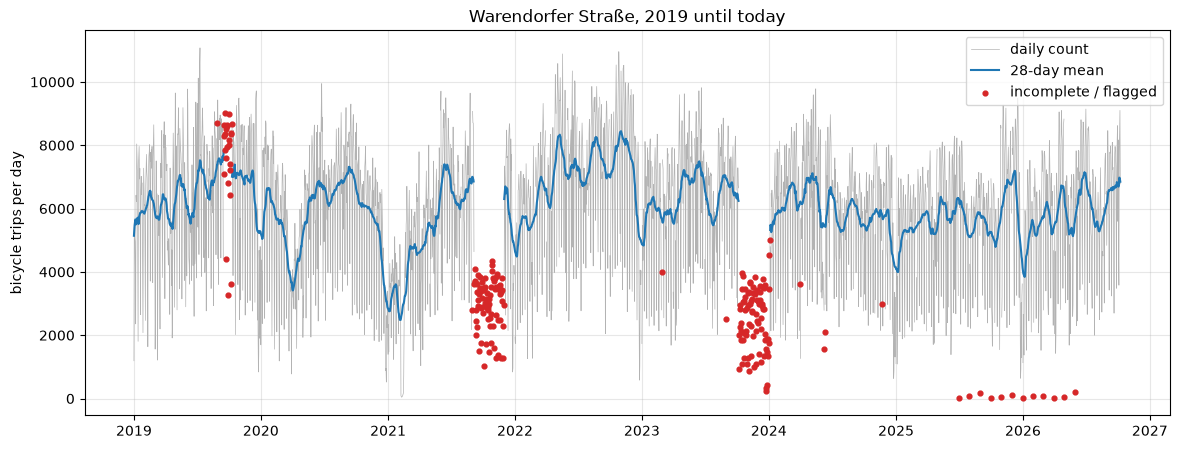

In [6]:
# Reindex to every calendar day so that excluded days become NaN.
# Otherwise matplotlib draws straight lines across the gaps, and rolling(28)
# would average 28 rows instead of 28 days.
ok = daily.loc[daily["complete"], "count"].reindex(all_days)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ok.index, ok, lw=0.5, color="0.7", label="daily count")
# A 28-day centred rolling mean smooths out the weekly pattern;
# min_periods=14 leaves it empty where more than half of the window is missing
ax.plot(ok.index, ok.rolling(28, center=True, min_periods=14).mean(), color="C0", label="28-day mean")
ax.scatter(bad.index, bad["count"], s=12, color="C3", zorder=3, label="incomplete / flagged")
ax.set_ylabel("bicycle trips per day")
ax.set_title("Warendorfer Straße, 2019 until today")
ax.legend()
ax.grid(alpha=0.3)
plt.show()